## Installation & Imports

In [23]:
%pip install -q tensorflow keras-tuner

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras_tuner as kt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
    LabelEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(42)


## Load Dataset

In [25]:
df = pd.read_csv("../data/student_mental_health.csv")

print("Dataset Shape:", df.shape)
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["Mental_Health_Risk"].value_counts())


Dataset Shape: (2000, 17)


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium



Missing Values:
Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

Target Distribution:
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


## Features & Target

In [26]:

df = df.drop(columns=["Student_ID"], errors="ignore")

X = df.drop(columns=["Mental_Health_Risk"])
y = df["Mental_Health_Risk"].astype(str).str.strip()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Classes: ['High' 'Low' 'Medium']
Features Shape: (2000, 15)
Target Shape: (2000,)


## Train / Validation / Test Split

In [27]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.10,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


Training: (1440, 15)
Validation: (360, 15)
Testing: (200, 15)


## Preprocessing Pipeline

In [28]:
numeric_cols = [
    "Age",
    "Year_of_Study",
    "Sleep_Hours",
    "Study_Hours_Per_Week",
    "GPA",
    "Social_Media_Hours",
    "Screen_Time_Hours",
    "Financial_Stress",
    "Family_Support",
    "Attendance_Rate"
]

nominal_cols = [
    "Gender",
    "Part_Time_Job",
    "Previous_Mental_Health_History"
]

ordinal_cols = [
    "Physical_Activity",
    "Diet_Quality"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

nominal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[
            ["Low", "Moderate", "High"],
            ["Poor", "Average", "Good"]
        ],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("nom", nominal_pipeline, nominal_cols),
    ("ord", ordinal_pipeline, ordinal_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training Processed:", X_train_processed.shape)
print("Validation Processed:", X_val_processed.shape)
print("Testing Processed:", X_test_processed.shape)


Training Processed: (1440, 19)
Validation Processed: (360, 19)
Testing Processed: (200, 19)


## Build Neural Network Model

In [29]:

def build_model(hp):

    model = keras.Sequential()

    model.add(
        layers.Input(shape=(X_train_processed.shape[1],))
    )

    num_layers = hp.Int(
        "num_layers",
        min_value=1,
        max_value=3,
        step=1
    )

    l2_value = hp.Choice(
        "l2",
        values=[0.0001, 0.001, 0.01, 0.1]
    )

    for i in range(num_layers):

        units = hp.Choice(
            f"units_{i}",
            values=[32, 64, 128, 256]
        )

        model.add(
            layers.Dense(
                units=units,
                activation="relu",
                kernel_regularizer=keras.regularizers.l2(l2_value)
            )
        )

        dropout_rate = hp.Float(
            f"dropout_{i}",
            min_value=0.0,
            max_value=0.5,
            step=0.1
        )

        if dropout_rate > 0:
            model.add(layers.Dropout(dropout_rate))

    model.add(
        layers.Dense(
            len(label_encoder.classes_),
            activation="softmax"
        )
    )

    learning_rate = hp.Choice(
        "learning_rate",
        values=[0.001, 0.0005, 0.0001]
    )

    optimizer_name = hp.Choice(
        "optimizer",
        values=["adam", "rmsprop"]
    )

    if optimizer_name == "adam":
        optimizer = keras.optimizers.Adam(
            learning_rate=learning_rate
        )
    else:
        optimizer = keras.optimizers.RMSprop(
            learning_rate=learning_rate
        )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


## Apply Keras Tuner

In [30]:

tuner = kt.RandomSearch(
    hypermodel=build_model,
    objective="val_loss",
    max_trials=20,
    executions_per_trial=1,
    directory="keras_tuner_results",
    project_name="student_mental_health_ann",
    overwrite=True,
    seed=42
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

tuner.search(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Trial 20 Complete [00h 00m 11s]
val_loss: 0.8045376539230347

Best val_loss So Far: 0.5626041293144226
Total elapsed time: 00h 03m 27s


## Display Best Hyperparameters

In [31]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best Hyperparameters:")

for key, value in best_hp.values.items():
    print(f"{key}: {value}")

best_model_from_tuner = tuner.get_best_models(num_models=1)[0]

print("\nBest Model Architecture:")
best_model_from_tuner.summary()


Best Hyperparameters:
num_layers: 2
l2: 0.0001
units_0: 64
dropout_0: 0.1
learning_rate: 0.0001
optimizer: adam
units_1: 32
dropout_1: 0.0

Best Model Architecture:


c:\Users\Youcode\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,459 (13.51 KB)

 Trainable params: 3,459 (13.51 KB)

 Non-trainable params: 0 (0.00 B)

## Train Best Model & Save History

In [32]:

model = build_model(best_hp)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    verbose=1
)


Epoch 1/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3903 - loss: 1.1088 - val_accuracy: 0.3750 - val_loss: 1.0721 - learning_rate: 1.0000e-04
Epoch 2/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4333 - loss: 1.0619 - val_accuracy: 0.4472 - val_loss: 1.0307 - learning_rate: 1.0000e-04
Epoch 3/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4625 - loss: 1.0282 - val_accuracy: 0.5306 - val_loss: 0.9944 - learning_rate: 1.0000e-04
Epoch 4/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5160 - loss: 0.9878 - val_accuracy: 0.5722 - val_loss: 0.9606 - learning_rate: 1.0000e-04
Epoch 5/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5618 - loss: 0.9501 - val_accuracy: 0.5778 - val_loss: 0.9304 - learning_rate: 1.0000e-04
Epoch 6/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5826 - loss: 0.9191 - val_accuracy: 0.5944 - val_loss: 0.9027 - learning_rate: 1.0000e-04
Epoch 7/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5951 

## Plot Training & Validation Graphs

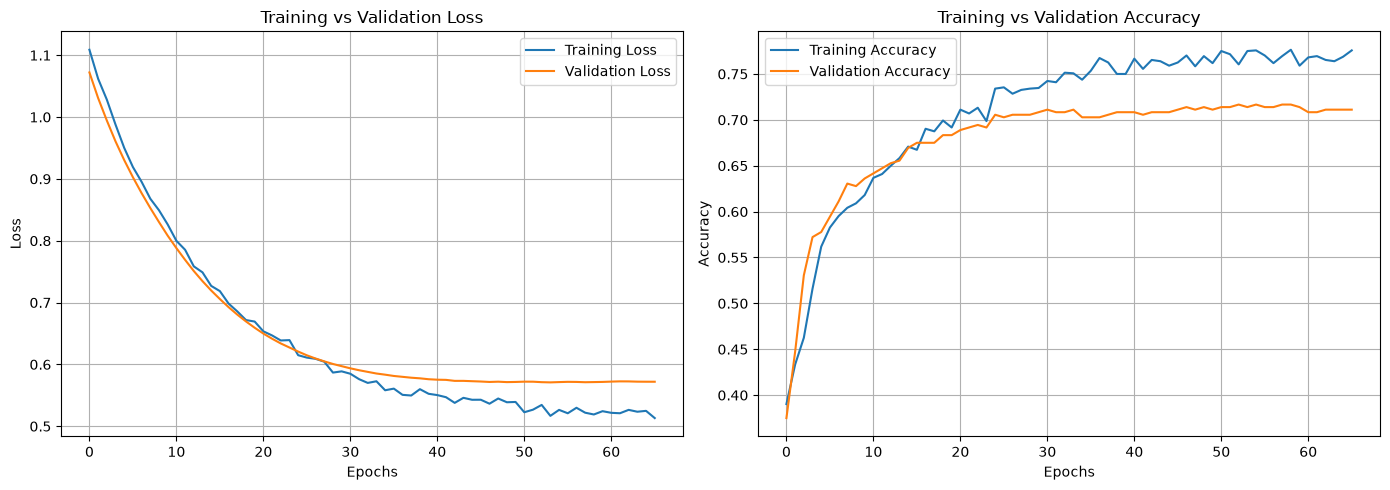

In [33]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["loss"], label="Training Loss")
axes[0].plot(history.history["val_loss"], label="Validation Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["accuracy"], label="Training Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


## Final Evaluation on Test Set

In [34]:

test_loss, test_accuracy = model.evaluate(
    X_test_processed,
    y_test,
    verbose=0
)

y_pred_proba = model.predict(
    X_test_processed,
    verbose=0
)

y_pred = np.argmax(y_pred_proba, axis=1)

print("TEST RESULTS")
print("=" * 40)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

print(f"Precision Macro: {precision_score(y_test, y_pred, average='macro'):.4f}")
print(f"Recall Macro:    {recall_score(y_test, y_pred, average='macro'):.4f}")
print(f"F1 Macro:        {f1_score(y_test, y_pred, average='macro'):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_,
        digits=4
    )
)


TEST RESULTS
Test Loss: 0.6056
Test Accuracy: 0.7300
Precision Macro: 0.7301
Recall Macro:    0.7291
F1 Macro:        0.7296

Classification Report:
              precision    recall  f1-score   support

        High     0.8358    0.8235    0.8296        68
         Low     0.7576    0.7576    0.7576        66
      Medium     0.5970    0.6061    0.6015        66

    accuracy                         0.7300       200
   macro avg     0.7301    0.7291    0.7296       200
weighted avg     0.7312    0.7300    0.7306       200



## Confusion Matrix

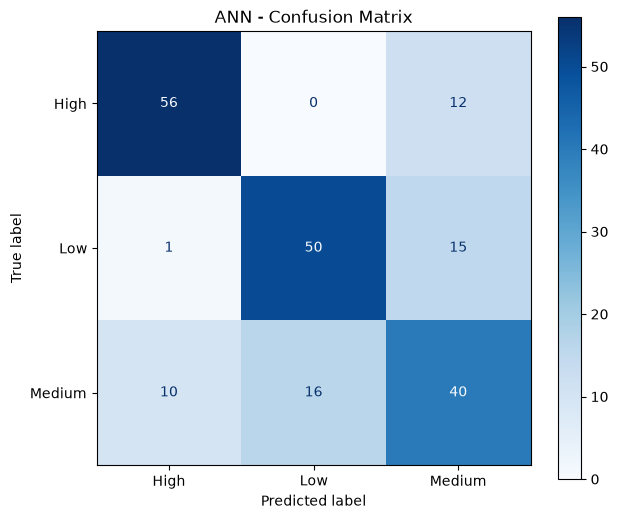

In [35]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    cmap="Blues",
    ax=ax,
    values_format="d"
)

plt.title("ANN - Confusion Matrix")
plt.show()
